Saving library_literature_dataset.csv to library_literature_dataset (1).csv
Dataset loaded successfully!
Dataset shape: (7800, 11)

Column names:
['User_ID', 'User_Type', 'Department', 'Academic_Level', 'Research_Area', 'Preferred_Language', 'Access_Frequency', 'Borrowing_Frequency', 'Avg_Reading_Time_Min', 'Device_Type', 'Recommendation_Status']


,User_ID,User_Type,Department,Academic_Level,Research_Area,Preferred_Language,Access_Frequency,Borrowing_Frequency,Avg_Reading_Time_Min,Device_Type,Recommendation_Status
0,U1000,Research Scholar,Civil,UG,Embedded Systems,English,High,Very Frequent,171,Desktop,Accepted
1,U1001,Library Staff,Chemistry,PG,Big Data,Tamil,Low,Occasional,21,Tablet,Accepted
2,U1002,Student,Physics,PhD,Cyber Security,Tamil,High,Frequent,63,Laptop,Accepted
3,U1003,Research Scholar,English,PhD,Big Data,Tamil,Low,Occasional,38,Mobile,Rejected
4,U1004,Research Scholar,Mechanical,UG,Software Engineering,Tamil,High,Occasional,171,Laptop,Rejected


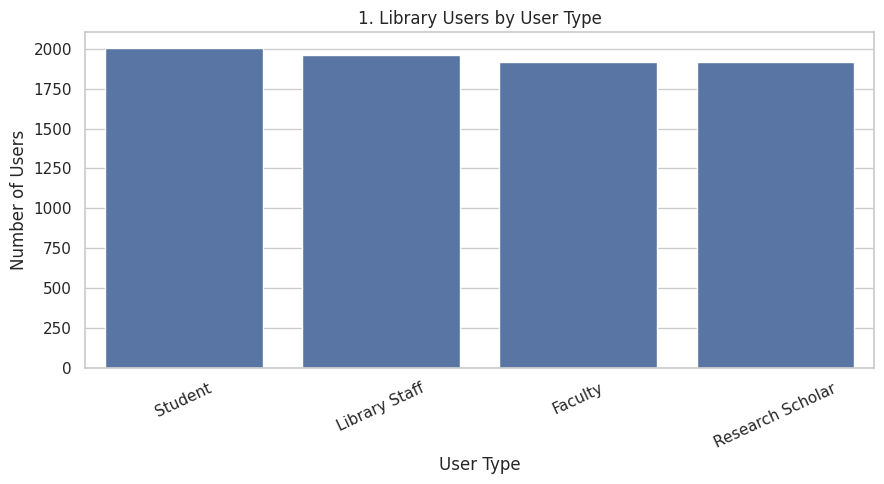

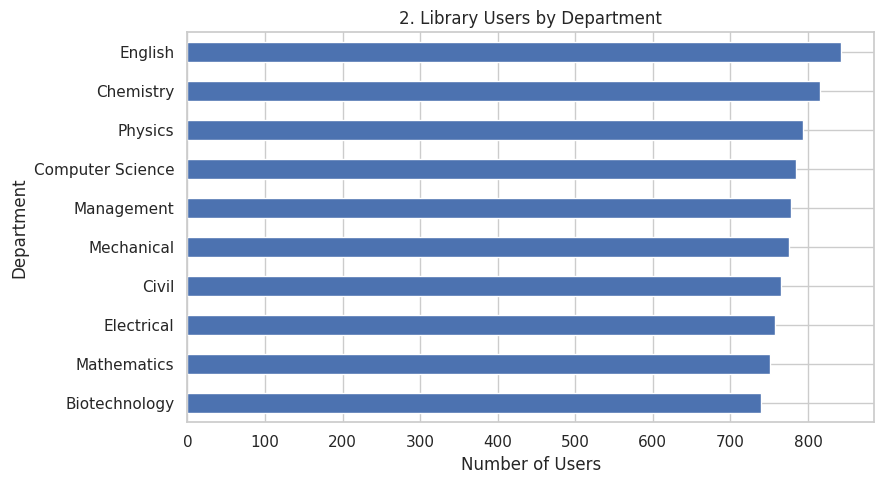

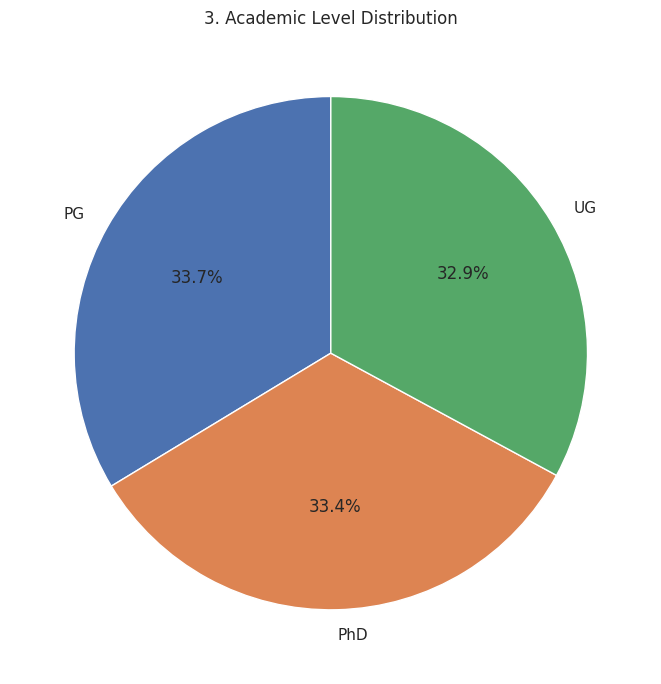

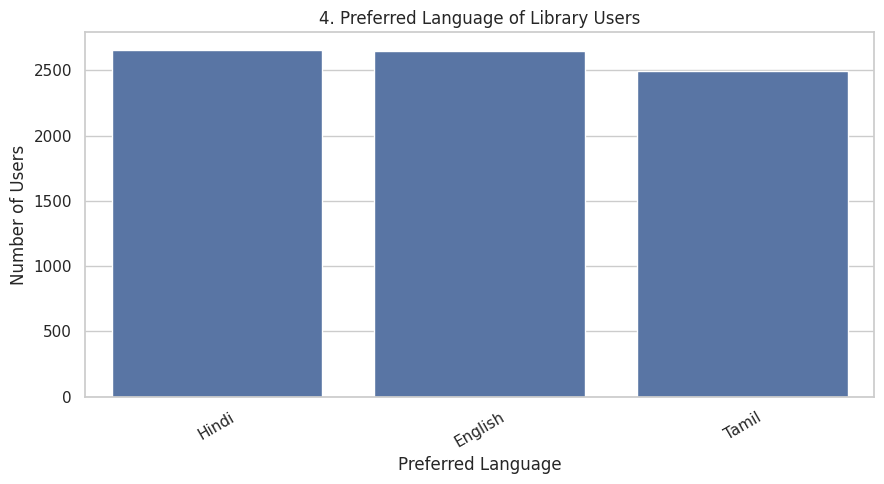

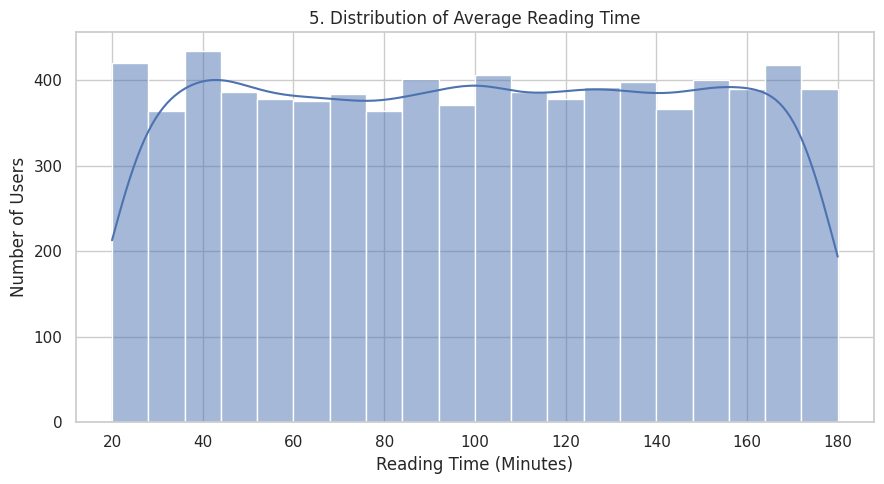

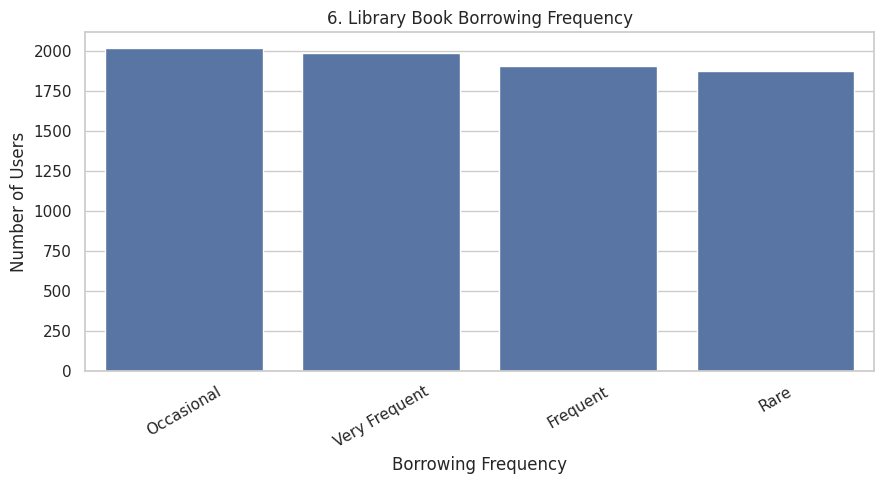

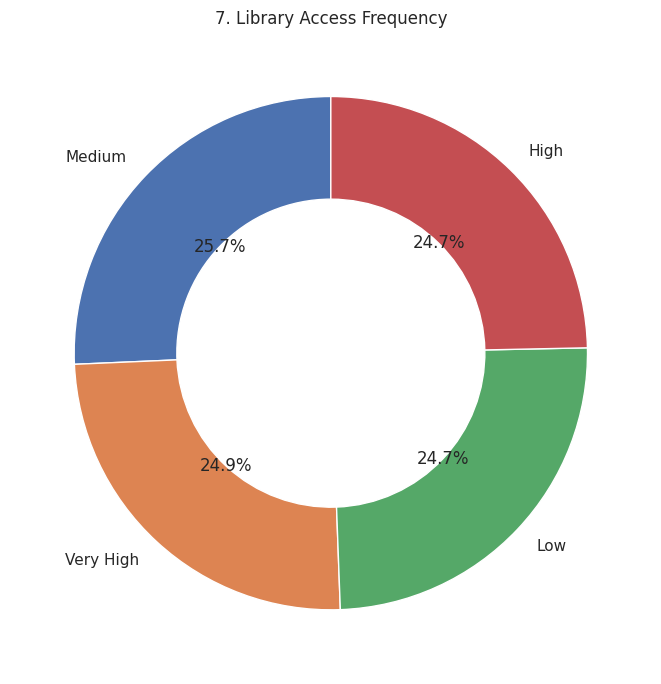

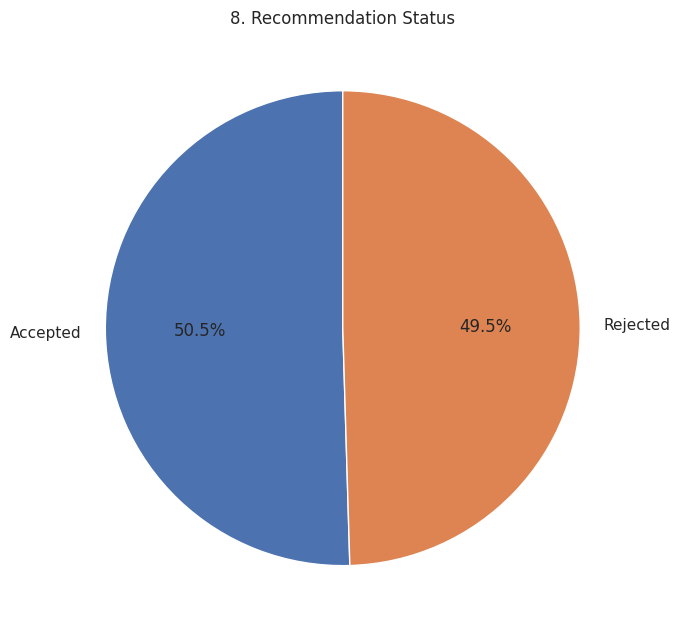

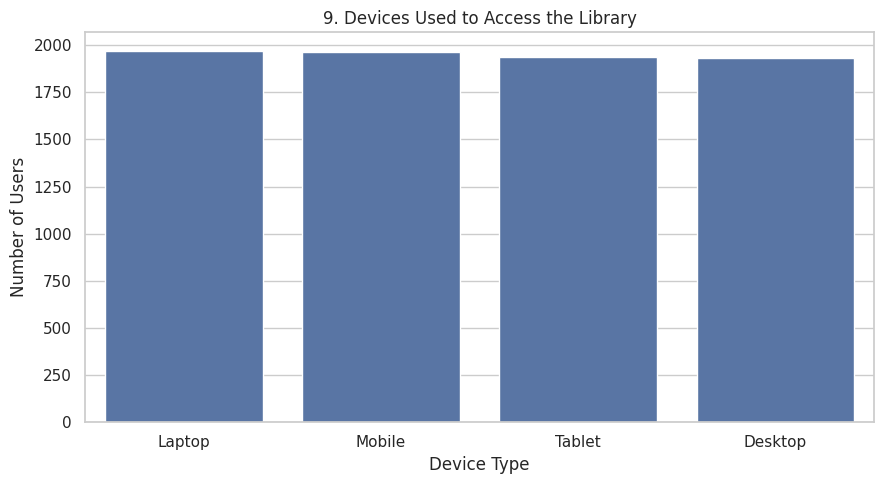

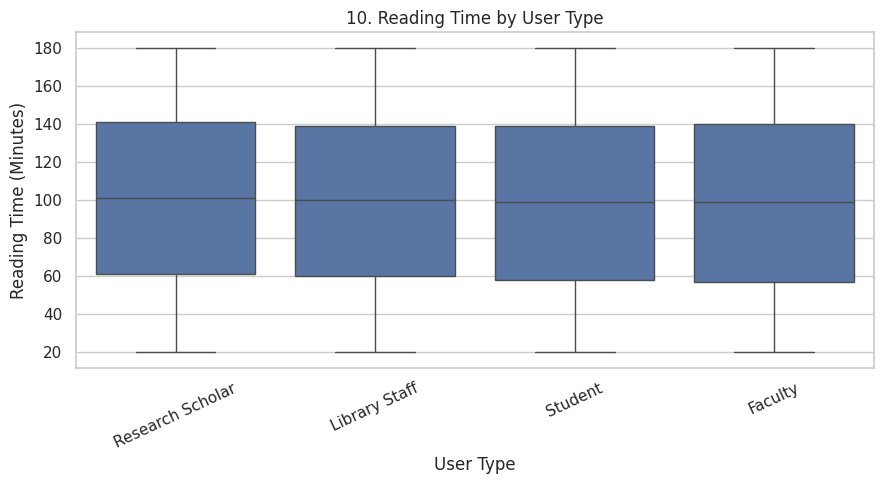

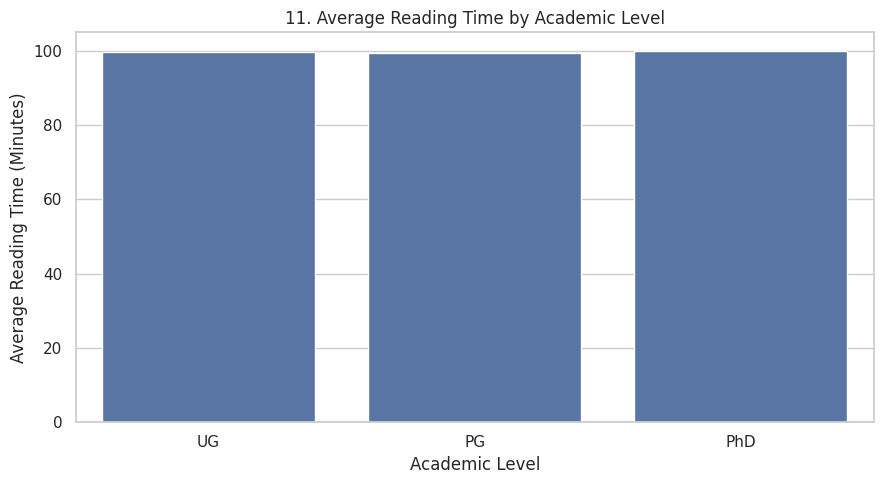

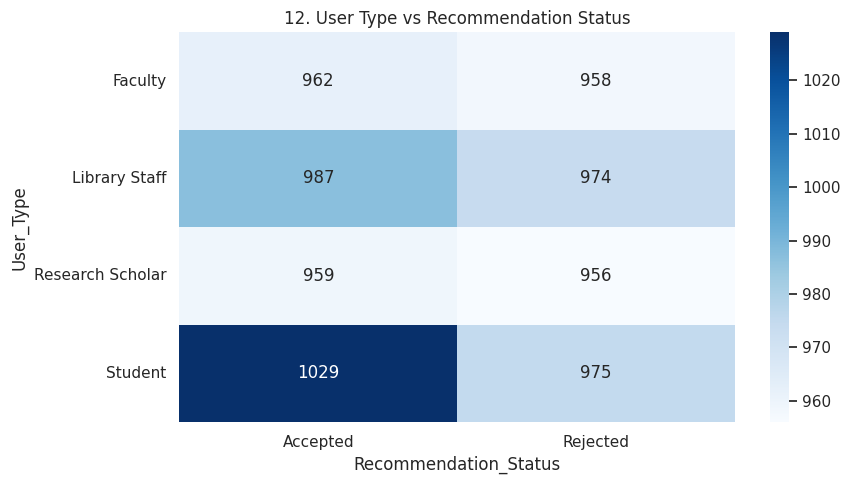

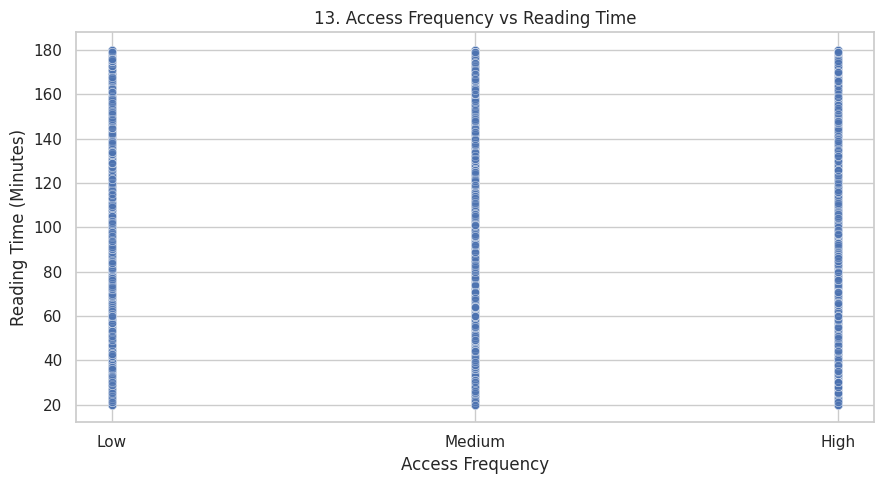

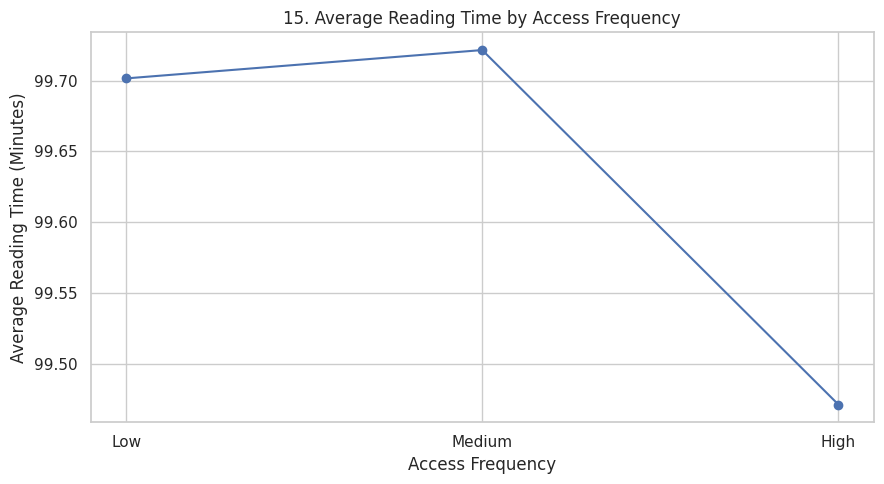

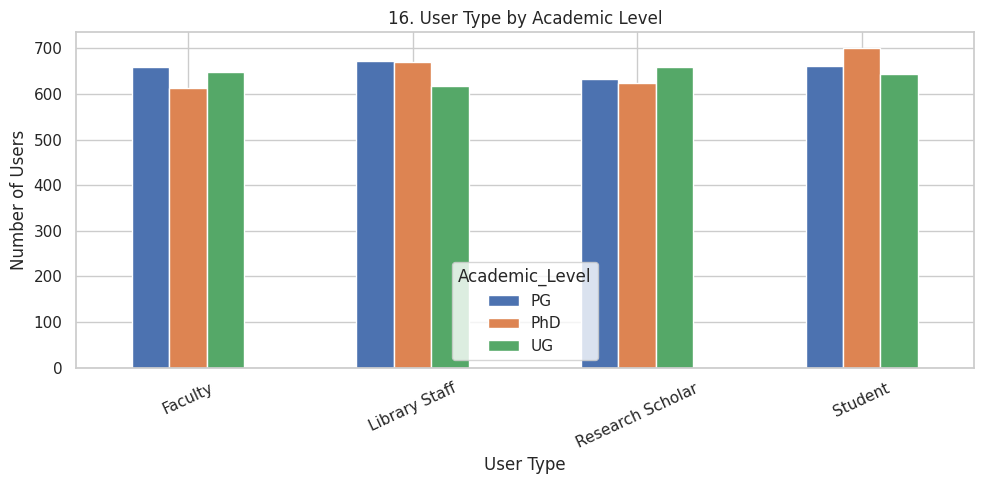

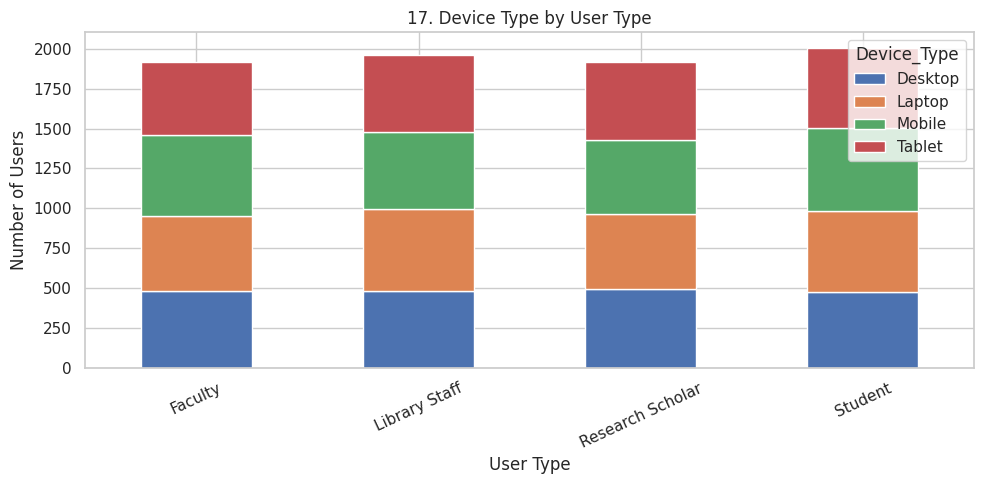

Correlation heatmap skipped: fewer than two numeric columns.

All available visualizations have been generated!
Total rows: 7800
Total columns: 11

Missing values by column:
User_ID                  0
User_Type                0
Department               0
Academic_Level           0
Research_Area            0
Preferred_Language       0
Access_Frequency         0
Borrowing_Frequency      0
Avg_Reading_Time_Min     0
Device_Type              0
Recommendation_Status    0
dtype: int64


In [2]:

# ============================================================
# SMART LIBRARY ANALYSIS - COMPLETE DATA VISUALIZATION PROJECT
# Google Colab: Upload CSV and run all charts in one cell
# ============================================================

!pip -q install plotly

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from google.colab import files
from IPython.display import display

# 1. UPLOAD AND LOAD DATASET
uploaded = files.upload()
filename = next(iter(uploaded))
df = pd.read_csv(filename)

# Clean column names and remove duplicate rows
df.columns = df.columns.str.strip()
df = df.drop_duplicates()

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())
display(df.head())

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 5)

# Expected Smart Library Analysis columns
required = [
    "User_Type", "Department", "Academic_Level", "Research_Area",
    "Preferred_Language", "Access_Frequency", "Borrowing_Frequency",
    "Avg_Reading_Time_Min", "Device_Type", "Recommendation_Status"
]

missing = [col for col in required if col not in df.columns]
if missing:
    print("Warning: These expected columns are missing:", missing)
    print("Please check the column names displayed above.")

# Convert reading time to numeric, where possible
if "Avg_Reading_Time_Min" in df.columns:
    df["Avg_Reading_Time_Min"] = pd.to_numeric(
        df["Avg_Reading_Time_Min"], errors="coerce"
    )

# ============================================================
# 2. BAR CHART - USERS BY USER TYPE
# ============================================================
if "User_Type" in df.columns:
    plt.figure()
    sns.countplot(data=df, x="User_Type", order=df["User_Type"].value_counts().index)
    plt.title("1. Library Users by User Type")
    plt.xlabel("User Type")
    plt.ylabel("Number of Users")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

# ============================================================
# 3. HORIZONTAL BAR CHART - USERS BY DEPARTMENT
# ============================================================
if "Department" in df.columns:
    plt.figure()
    df["Department"].value_counts().sort_values().plot(kind="barh")
    plt.title("2. Library Users by Department")
    plt.xlabel("Number of Users")
    plt.ylabel("Department")
    plt.tight_layout()
    plt.show()

# ============================================================
# 4. PIE CHART - ACADEMIC LEVEL
# ============================================================
if "Academic_Level" in df.columns:
    counts = df["Academic_Level"].value_counts()
    plt.figure(figsize=(7, 7))
    plt.pie(counts, labels=counts.index, autopct="%1.1f%%", startangle=90)
    plt.title("3. Academic Level Distribution")
    plt.tight_layout()
    plt.show()

# ============================================================
# 5. BAR CHART - PREFERRED LANGUAGE
# ============================================================
if "Preferred_Language" in df.columns:
    plt.figure()
    sns.countplot(
        data=df, x="Preferred_Language",
        order=df["Preferred_Language"].value_counts().index
    )
    plt.title("4. Preferred Language of Library Users")
    plt.xlabel("Preferred Language")
    plt.ylabel("Number of Users")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ============================================================
# 6. HISTOGRAM - READING TIME DISTRIBUTION
# ============================================================
if "Avg_Reading_Time_Min" in df.columns:
    plt.figure()
    sns.histplot(df["Avg_Reading_Time_Min"].dropna(), bins=20, kde=True)
    plt.title("5. Distribution of Average Reading Time")
    plt.xlabel("Reading Time (Minutes)")
    plt.ylabel("Number of Users")
    plt.tight_layout()
    plt.show()

# ============================================================
# 7. BAR CHART - BORROWING FREQUENCY
# ============================================================
if "Borrowing_Frequency" in df.columns:
    plt.figure()
    sns.countplot(
        data=df, x="Borrowing_Frequency",
        order=df["Borrowing_Frequency"].value_counts().index
    )
    plt.title("6. Library Book Borrowing Frequency")
    plt.xlabel("Borrowing Frequency")
    plt.ylabel("Number of Users")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

# ============================================================
# 8. DONUT CHART - ACCESS FREQUENCY
# ============================================================
if "Access_Frequency" in df.columns:
    counts = df["Access_Frequency"].value_counts()
    plt.figure(figsize=(7, 7))
    plt.pie(
        counts.values, labels=counts.index, autopct="%1.1f%%",
        startangle=90, wedgeprops={"width": 0.4}
    )
    plt.title("7. Library Access Frequency")
    plt.tight_layout()
    plt.show()

# ============================================================
# 9. PIE CHART - RECOMMENDATION STATUS
# ============================================================
if "Recommendation_Status" in df.columns:
    counts = df["Recommendation_Status"].value_counts()
    plt.figure(figsize=(7, 7))
    plt.pie(counts.values, labels=counts.index, autopct="%1.1f%%",
            startangle=90)
    plt.title("8. Recommendation Status")
    plt.tight_layout()
    plt.show()

# ============================================================
# 10. COUNT PLOT - DEVICE TYPE
# ============================================================
if "Device_Type" in df.columns:
    plt.figure()
    sns.countplot(
        data=df, x="Device_Type",
        order=df["Device_Type"].value_counts().index
    )
    plt.title("9. Devices Used to Access the Library")
    plt.xlabel("Device Type")
    plt.ylabel("Number of Users")
    plt.tight_layout()
    plt.show()

# ============================================================
# 11. BOX PLOT - READING TIME BY USER TYPE
# ============================================================
if {"User_Type", "Avg_Reading_Time_Min"}.issubset(df.columns):
    plt.figure()
    sns.boxplot(data=df, x="User_Type", y="Avg_Reading_Time_Min")
    plt.title("10. Reading Time by User Type")
    plt.xlabel("User Type")
    plt.ylabel("Reading Time (Minutes)")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

# ============================================================
# 12. BAR CHART - AVERAGE READING TIME BY ACADEMIC LEVEL
# ============================================================
if {"Academic_Level", "Avg_Reading_Time_Min"}.issubset(df.columns):
    plt.figure()
    sns.barplot(
        data=df, x="Academic_Level", y="Avg_Reading_Time_Min",
        errorbar=None
    )
    plt.title("11. Average Reading Time by Academic Level")
    plt.xlabel("Academic Level")
    plt.ylabel("Average Reading Time (Minutes)")
    plt.tight_layout()
    plt.show()

# ============================================================
# 13. HEATMAP - USER TYPE VS RECOMMENDATION STATUS
# ============================================================
if {"User_Type", "Recommendation_Status"}.issubset(df.columns):
    heatmap_data = pd.crosstab(
        df["User_Type"], df["Recommendation_Status"]
    )
    plt.figure(figsize=(9, 5))
    sns.heatmap(heatmap_data, annot=True, fmt="d", cmap="Blues")
    plt.title("12. User Type vs Recommendation Status")
    plt.tight_layout()
    plt.show()

# ============================================================
# 14. SCATTER PLOT - ACCESS FREQUENCY VS READING TIME
# ============================================================
if {"Access_Frequency", "Avg_Reading_Time_Min"}.issubset(df.columns):
    access_order = {"Low": 1, "Medium": 2, "High": 3}
    scatter_df = df.copy()
    scatter_df["Access_Score"] = (
        scatter_df["Access_Frequency"].astype(str).str.strip().str.title()
        .map(access_order)
    )
    scatter_df = scatter_df.dropna(
        subset=["Access_Score", "Avg_Reading_Time_Min"]
    )

    if not scatter_df.empty:
        plt.figure()
        sns.scatterplot(
            data=scatter_df, x="Access_Score",
            y="Avg_Reading_Time_Min", alpha=0.5
        )
        plt.xticks([1, 2, 3], ["Low", "Medium", "High"])
        plt.title("13. Access Frequency vs Reading Time")
        plt.xlabel("Access Frequency")
        plt.ylabel("Reading Time (Minutes)")
        plt.tight_layout()
        plt.show()
    else:
        print("Scatter plot skipped: Access Frequency values were not Low/Medium/High.")



# ============================================================
# 16. LINE CHART - AVERAGE READING TIME BY ACCESS FREQUENCY
# ============================================================
if {"Access_Frequency", "Avg_Reading_Time_Min"}.issubset(df.columns):
    access_order = ["Low", "Medium", "High"]
    line_df = (
        df.assign(
            Access_Frequency=df["Access_Frequency"].astype(str).str.strip().str.title()
        )
        .groupby("Access_Frequency", observed=True)["Avg_Reading_Time_Min"]
        .mean()
        .reindex(access_order)
        .dropna()
    )

    if not line_df.empty:
        plt.figure()
        plt.plot(line_df.index, line_df.values, marker="o")
        plt.title("15. Average Reading Time by Access Frequency")
        plt.xlabel("Access Frequency")
        plt.ylabel("Average Reading Time (Minutes)")
        plt.tight_layout()
        plt.show()

# ============================================================
# 17. GROUPED BAR CHART - USER TYPE VS ACADEMIC LEVEL
# ============================================================
if {"User_Type", "Academic_Level"}.issubset(df.columns):
    grouped = pd.crosstab(df["User_Type"], df["Academic_Level"])
    grouped.plot(kind="bar", figsize=(10, 5))
    plt.title("16. User Type by Academic Level")
    plt.xlabel("User Type")
    plt.ylabel("Number of Users")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

# ============================================================
# 18. STACKED BAR CHART - USER TYPE VS DEVICE TYPE
# ============================================================
if {"User_Type", "Device_Type"}.issubset(df.columns):
    stacked = pd.crosstab(df["User_Type"], df["Device_Type"])
    stacked.plot(kind="bar", stacked=True, figsize=(10, 5))
    plt.title("17. Device Type by User Type")
    plt.xlabel("User Type")
    plt.ylabel("Number of Users")
    plt.xticks(rotation=25)
    plt.tight_layout()
    plt.show()

# ============================================================
# 19. INTERACTIVE TREEMAP - DEPARTMENT AND RESEARCH AREA
# ============================================================
if {"Department", "Research_Area"}.issubset(df.columns):
    treemap_df = (
        df.groupby(["Department", "Research_Area"])
        .size().reset_index(name="User_Count")
    )
    fig = px.treemap(
        treemap_df,
        path=["Department", "Research_Area"],
        values="User_Count",
        title="18. Library Users by Department and Research Area"
    )
    fig.show()

# ============================================================
# 20. INTERACTIVE SUNBURST - DEPARTMENT, RESEARCH AREA
# ============================================================
if {"Department", "Research_Area"}.issubset(df.columns):
    fig = px.sunburst(
        df,
        path=["Department", "Research_Area"],
        title="19. Department and Research Area Distribution"
    )
    fig.show()

# ============================================================
# 21. INTERACTIVE BAR CHART - RESEARCH AREA
# ============================================================
if "Research_Area" in df.columns:
    research_counts = (
        df["Research_Area"].value_counts()
        .rename_axis("Research_Area")
        .reset_index(name="User_Count")
    )
    fig = px.bar(
        research_counts,
        x="Research_Area", y="User_Count",
        text="User_Count", title="20. Library Users by Research Area"
    )
    fig.update_layout(xaxis_tickangle=-35)
    fig.show()

# ============================================================
# 22. CORRELATION HEATMAP - NUMERIC COLUMNS
# ============================================================
numeric_df = df.select_dtypes(include="number").drop(
    columns=["User_ID"], errors="ignore"
)

if numeric_df.shape[1] >= 2:
    plt.figure(figsize=(8, 5))
    sns.heatmap(
        numeric_df.corr(), annot=True, cmap="coolwarm",
        fmt=".2f", vmin=-1, vmax=1
    )
    plt.title("21. Correlation Heatmap of Numeric Features")
    plt.tight_layout()
    plt.show()
else:
    print("Correlation heatmap skipped: fewer than two numeric columns.")

# ============================================================
# 23. SUMMARY
# ============================================================
print("\nAll available visualizations have been generated!")
print("Total rows:", len(df))
print("Total columns:", len(df.columns))
print("\nMissing values by column:")
print(df.isnull().sum())
